# Clyvo Vet — Vigia B: alerta individual

# Parte 1 — Análise exploratória

## 1. Importação das bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

from clyvo_features import (carregar_referencias, consumo_esperado, extrair_features, causa_provavel,
                            FEATURES_NUMERICAS, FEATURES_CATEGORICAS)

referencias = carregar_referencias()
print("Referências carregadas de:", referencias["origem"])

Referências carregadas de: planilhas (referencias/)


## 2. Carregando os dados

In [2]:
df = pd.read_csv("dataset_vigia_b.csv")
print("Formato:", df.shape)
df.head()

Formato: (8000, 28)


,especie,raca,idade_anos,peso_kg,castrado,desvio_peso,castrado_perto_limite,comida_vs_esperado,agua_vs_esperado,comida_vs_baseline,...,predisp_forte,sinal_tardio,vacinas_atrasadas,vacina_doenca_regional,dias_sem_consulta,alerta_regional,sexo,perfil_simulado,suspeita_principal,nivel_risco
0,Felina,Persa,14.46,2.94,0,0.0000,0,1.1287,0.9486,1.0277,...,0,0,0,0,523,0,F,normal,nenhuma,BAIXO
1,Canina,Schnauzer Miniatura,10.95,9.33,0,0.0249,0,1.0080,0.8753,1.0556,...,0,0,0,0,330,0,F,normal,nenhuma,BAIXO
2,Felina,Exótico,14.24,3.11,1,0.0000,1,1.0002,1.3122,1.0495,...,1,0,1,0,274,1,F,Doença renal policística,predisposicao confirmada,ALTO
3,Canina,Schnauzer Miniatura,6.80,9.24,0,0.0149,0,0.9961,0.8720,0.9718,...,0,0,1,0,620,0,F,normal,nenhuma,BAIXO
4,Canina,Shar-Pei,4.28,21.58,1,0.0000,0,0.8716,0.9083,0.8604,...,0,0,1,0,145,0,F,leve,nenhuma,BAIXO


### Quantidade de animais por nível de risco

In [3]:
contagem = df["nivel_risco"].value_counts()
porcentagem = (contagem / len(df) * 100).round(1)
(contagem.astype(str) + " (" + porcentagem.astype(str) + "%)").to_frame("animais")

,animais
nivel_risco,
BAIXO,4908 (61.4%)
MEDIO,1688 (21.1%)
ALTO,1404 (17.5%)


### Quantidade de animais por nível de risco, em cada condição simulada

In [4]:
pd.crosstab(df["perfil_simulado"], df["nivel_risco"])[["BAIXO", "MEDIO", "ALTO"]]

nivel_risco,BAIXO,MEDIO,ALTO
perfil_simulado,,,
Artrose,83,47,61
Cardiomiopatia hipertrófica,211,62,6
Diabetes mellitus,11,19,41
Doença degenerativa da válvula mitral,106,21,3
Doença renal policística,46,51,106
Hipoadrenocorticismo (Addison),29,97,270
Hipotireoidismo,121,71,85
Obesidade,7,117,257
Síndrome de Cushing,19,26,39


### Quantidade de animais com e sem vacina atrasada para doença em surto no bairro, por nível de risco

In [5]:
vacina_atrasada = df["vacina_doenca_regional"].map({0: "não", 1: "sim"})
quantidade = pd.crosstab(vacina_atrasada, df["nivel_risco"])[["BAIXO", "MEDIO", "ALTO"]]
porcentagem = (pd.crosstab(vacina_atrasada, df["nivel_risco"], normalize="index")[["BAIXO", "MEDIO", "ALTO"]] * 100).round(1)
quantidade.astype(str) + " (" + porcentagem.astype(str) + "%)"

nivel_risco,BAIXO,MEDIO,ALTO
vacina_doenca_regional,,,
não,4873 (63.2%),1539 (20.0%),1293 (16.8%)
sim,35 (11.9%),149 (50.5%),111 (37.6%)


### Média de cada correlação por nível de risco

In [6]:
correlacoes_comparadas = ["comida_vs_esperado", "agua_vs_esperado", "tend_mov", "tend_agua",
                             "predisp_sinal_alterado", "castrado_perto_limite", "vacina_doenca_regional", "dias_sem_consulta"]
resumo = df.groupby("nivel_risco")[correlacoes_comparadas].mean()
resumo.insert(0, "desvio_peso (absoluto)", df["desvio_peso"].abs().groupby(df["nivel_risco"]).mean())
resumo.loc[["BAIXO", "MEDIO", "ALTO"]].round(3)

,desvio_peso (absoluto),comida_vs_esperado,agua_vs_esperado,tend_mov,tend_agua,predisp_sinal_alterado,castrado_perto_limite,vacina_doenca_regional,dias_sem_consulta
nivel_risco,,,,,,,,,
BAIXO,0.006,0.975,1.001,-0.029,-0.001,0.005,0.215,0.007,285.372
MEDIO,0.041,0.934,1.010,-0.073,-0.010,0.134,0.255,0.088,280.313
ALTO,0.075,0.912,1.021,-0.152,0.000,0.435,0.291,0.079,310.437


# Parte 2 — Treinamento

## 3. Preparação dos dados

In [7]:
X = df[FEATURES_CATEGORICAS + FEATURES_NUMERICAS]
y = df["nivel_risco"]

print(f"Perguntas da ficha: {X.shape[1]} ({len(FEATURES_CATEGORICAS)} de texto e {len(FEATURES_NUMERICAS)} numéricas)")
X.head()

Perguntas da ficha: 24 (2 de texto e 22 numéricas)


,especie,raca,idade_anos,peso_kg,castrado,desvio_peso,castrado_perto_limite,comida_vs_esperado,agua_vs_esperado,comida_vs_baseline,...,tend_agua,tend_mov,idade_risco,predisp_sinal_alterado,predisp_forte,sinal_tardio,vacinas_atrasadas,vacina_doenca_regional,dias_sem_consulta,alerta_regional
0,Felina,Persa,14.46,2.94,0,0.0000,0,1.1287,0.9486,1.0277,...,-0.0403,-0.1384,1,0,0,0,0,0,523,0
1,Canina,Schnauzer Miniatura,10.95,9.33,0,0.0249,0,1.0080,0.8753,1.0556,...,0.0416,-0.0541,1,0,0,0,0,0,330,0
2,Felina,Exótico,14.24,3.11,1,0.0000,1,1.0002,1.3122,1.0495,...,0.4155,-0.1136,1,1,1,0,1,0,274,1
3,Canina,Schnauzer Miniatura,6.80,9.24,0,0.0149,0,0.9961,0.8720,0.9718,...,-0.0307,-0.0884,1,0,0,0,1,0,620,0
4,Canina,Shar-Pei,4.28,21.58,1,0.0000,0,0.8716,0.9083,0.8604,...,0.0100,-0.1583,0,0,0,0,1,0,145,0


### Pipeline: OneHotEncoder + modelo (transforma espécie e raça em 0/1)

In [8]:
def montar_pipeline(modelo):
    """Junta a transformação de espécie e raça em 0/1 (OneHotEncoder) e o modelo."""
    preparacao = ColumnTransformer(
        [("numericas", "passthrough", FEATURES_NUMERICAS),
         ("texto_para_0_1", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FEATURES_CATEGORICAS)],
        verbose_feature_names_out=False)
    return Pipeline([("preparacao", preparacao), ("modelo", modelo)])


colunas_modelo = montar_pipeline(None).named_steps["preparacao"].fit(X).get_feature_names_out()
print("Colunas de entrada do modelo:", len(colunas_modelo))

Colunas de entrada do modelo: 48


## 4. Separação em treino e teste (80/20)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Treino:", X_train.shape[0], "animais")
print("Teste: ", X_test.shape[0], "animais")

Treino: 6400 animais
Teste:  1600 animais


## 5. Árvore de Decisão

### 5.1 Profundidade: treino x teste

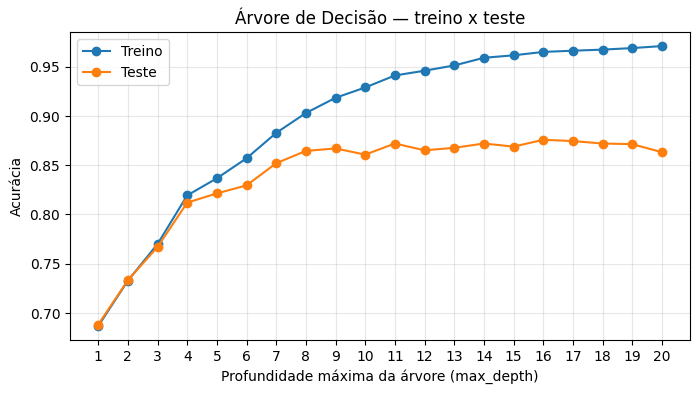

Maior acurácia no teste: profundidade 16 (0.876)
Profundidade 8: 0.864 no teste e 0.903 no treino


In [10]:
profundidades = range(1, 21)
acc_treino, acc_teste = [], []

for p in profundidades:
    arvore_teste = montar_pipeline(DecisionTreeClassifier(max_depth=p, random_state=42))
    arvore_teste.fit(X_train, y_train)
    acc_treino.append(accuracy_score(y_train, arvore_teste.predict(X_train)))
    acc_teste.append(accuracy_score(y_test, arvore_teste.predict(X_test)))

plt.figure(figsize=(8, 4))
plt.plot(profundidades, acc_treino, marker="o", label="Treino")
plt.plot(profundidades, acc_teste, marker="o", label="Teste")
plt.xlabel("Profundidade máxima da árvore (max_depth)")
plt.ylabel("Acurácia")
plt.title("Árvore de Decisão — treino x teste")
plt.xticks(list(profundidades))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

melhor_profundidade = list(profundidades)[int(np.argmax(acc_teste))]
print(f"Maior acurácia no teste: profundidade {melhor_profundidade} ({max(acc_teste):.3f})")
print(f"Profundidade 8: {acc_teste[7]:.3f} no teste e {acc_treino[7]:.3f} no treino")

### 5.2 Teste das combinações de parâmetros (GridSearchCV): profundidades 4, 6, 8, 10 e 12, com validação cruzada

In [11]:
grade_arvore = {
    "modelo__criterion": ["gini", "entropy"],
    "modelo__max_depth": [4, 6, 8, 10, 12],
    "modelo__min_samples_split": [2, 10, 20],
    "modelo__min_samples_leaf": [1, 5, 10],
}
busca_arvore = GridSearchCV(montar_pipeline(DecisionTreeClassifier(random_state=42)), grade_arvore, cv=5, n_jobs=-1)
busca_arvore.fit(X_train, y_train)

print("Melhor combinação geral:", busca_arvore.best_params_)
print(f"Acurácia média na validação cruzada: {busca_arvore.best_score_:.3f}")

resultados = pd.DataFrame(busca_arvore.cv_results_)
por_profundidade = (resultados.groupby("param_modelo__max_depth")["mean_test_score"].max()
                    .rename("melhor acurácia (validação cruzada)").round(3))
por_profundidade.to_frame()

Melhor combinação geral: {'modelo__criterion': 'entropy', 'modelo__max_depth': 12, 'modelo__min_samples_leaf': 5, 'modelo__min_samples_split': 20}
Acurácia média na validação cruzada: 0.873


,melhor acurácia (validação cruzada)
param_modelo__max_depth,
4,0.814
6,0.841
8,0.862
10,0.871
12,0.873


### 5.3 Parâmetros escolhidos: melhor combinação com 8 níveis

In [12]:
melhores_8 = (resultados[resultados["param_modelo__max_depth"] == 8]
              .sort_values("mean_test_score", ascending=False).iloc[0]["params"])
print("Parâmetros escolhidos para a árvore:", melhores_8)

Parâmetros escolhidos para a árvore: {'modelo__criterion': 'gini', 'modelo__max_depth': 8, 'modelo__min_samples_leaf': 5, 'modelo__min_samples_split': 2}


### 5.4 Treinamento e avaliação da árvore

In [13]:
arvore = montar_pipeline(DecisionTreeClassifier(random_state=42)).set_params(**melhores_8)
arvore.fit(X_train, y_train)

y_pred_arvore = arvore.predict(X_test)
acc_arvore = accuracy_score(y_test, y_pred_arvore)

print(f"Acurácia da Árvore de Decisão: {acc_arvore:.3f}\n")
print(classification_report(y_test, y_pred_arvore))

Acurácia da Árvore de Decisão: 0.865

              precision    recall  f1-score   support

        ALTO       0.84      0.84      0.84       281
       BAIXO       0.90      0.98      0.94       981
       MEDIO       0.75      0.56      0.64       338

    accuracy                           0.86      1600
   macro avg       0.83      0.79      0.81      1600
weighted avg       0.86      0.86      0.86      1600



### 5.5 Visualização da árvore

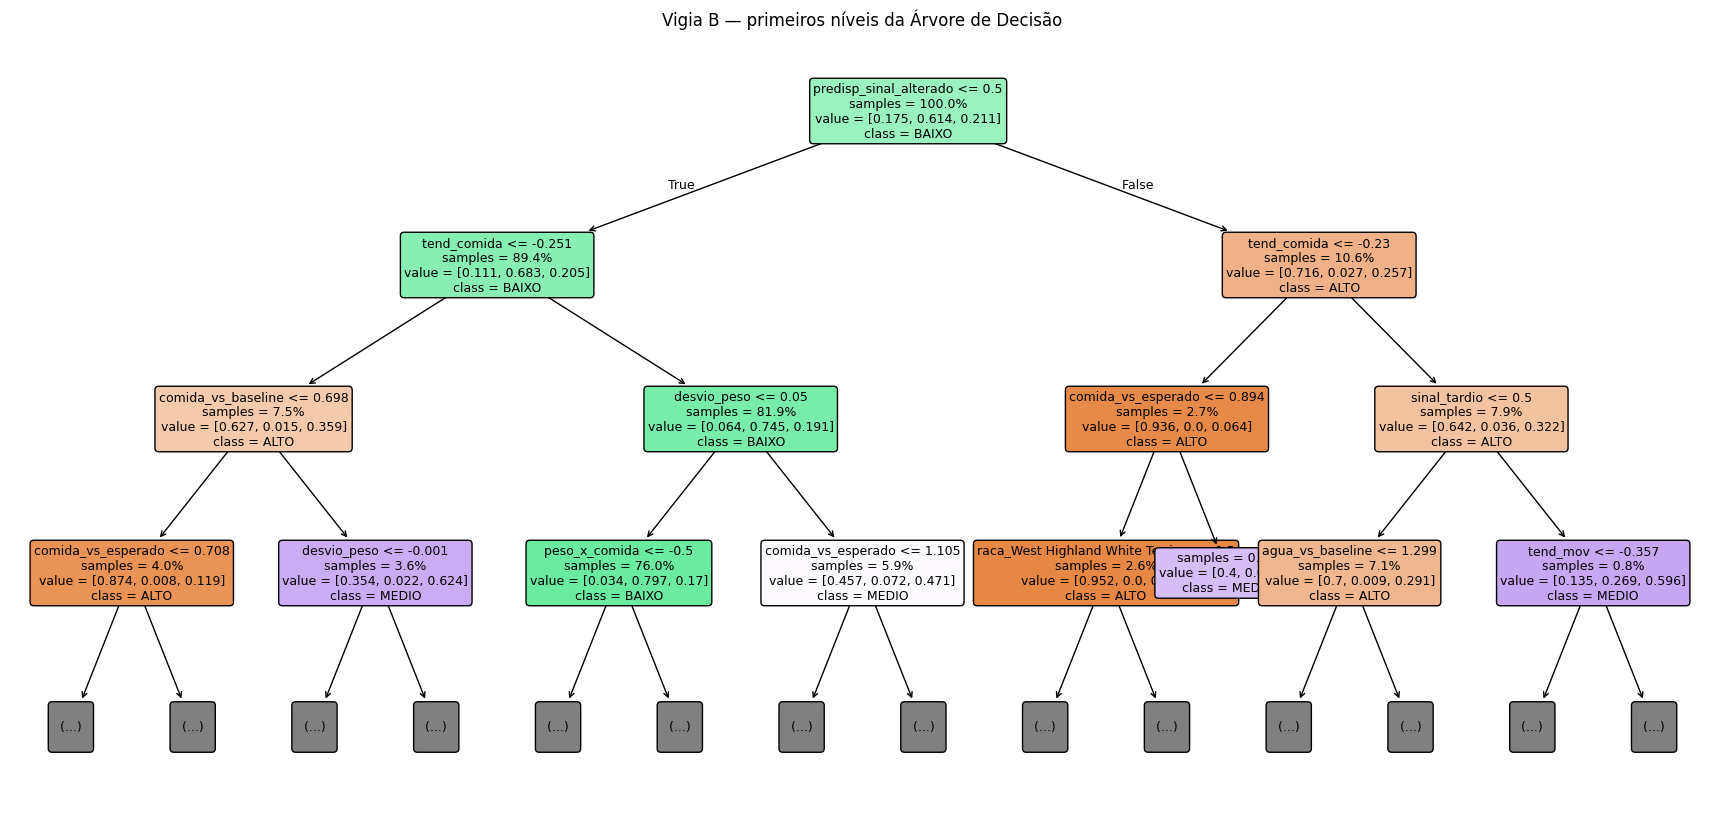

In [14]:
plt.figure(figsize=(22, 10))
plot_tree(arvore.named_steps["modelo"], max_depth=3, feature_names=colunas_modelo, class_names=arvore.classes_,
          filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title("Vigia B — primeiros níveis da Árvore de Decisão")
plt.show()

## 6. Random Forest

### 6.1 Teste das combinações de parâmetros: número de árvores, profundidade e colunas por pergunta, com validação cruzada

In [15]:
grade_floresta = {
    "modelo__n_estimators": [100, 200],
    "modelo__max_depth": [8, 12, None],
    "modelo__max_features": [0.5, "sqrt"],
}
busca_floresta = GridSearchCV(montar_pipeline(RandomForestClassifier(random_state=42, n_jobs=-1)), grade_floresta, cv=5)
busca_floresta.fit(X_train, y_train)

print("Parâmetros escolhidos para o Random Forest:", busca_floresta.best_params_)
print(f"Acurácia média na validação cruzada: {busca_floresta.best_score_:.3f}")

resultados_floresta = pd.DataFrame(busca_floresta.cv_results_)[
    ["param_modelo__n_estimators", "param_modelo__max_depth", "param_modelo__max_features", "mean_test_score"]]
resultados_floresta.columns = ["árvores", "profundidade", "colunas por pergunta", "acurácia (validação cruzada)"]
resultados_floresta.sort_values("acurácia (validação cruzada)", ascending=False).round(3).head(6)

Parâmetros escolhidos para o Random Forest: {'modelo__max_depth': None, 'modelo__max_features': 0.5, 'modelo__n_estimators': 200}
Acurácia média na validação cruzada: 0.888


,árvores,profundidade,colunas por pergunta,acurácia (validação cruzada)
9,200,None,0.5,0.888
8,100,None,0.5,0.887
5,200,12,0.5,0.884
4,100,12,0.5,0.883
11,200,None,sqrt,0.875
10,100,None,sqrt,0.874


### 6.2 Avaliação do Random Forest escolhido no teste

In [16]:
floresta = busca_floresta.best_estimator_

y_pred_floresta = floresta.predict(X_test)
acc_floresta = accuracy_score(y_test, y_pred_floresta)

print(f"Acurácia do Random Forest: {acc_floresta:.3f}\n")
print(classification_report(y_test, y_pred_floresta))

Acurácia do Random Forest: 0.891

              precision    recall  f1-score   support

        ALTO       0.86      0.86      0.86       281
       BAIXO       0.93      0.97      0.95       981
       MEDIO       0.78      0.68      0.73       338

    accuracy                           0.89      1600
   macro avg       0.86      0.84      0.85      1600
weighted avg       0.89      0.89      0.89      1600



## 7. Comparação entre os modelos (validação cruzada)

In [17]:
cv_arvore = cross_val_score(montar_pipeline(DecisionTreeClassifier(random_state=42)).set_params(**melhores_8),
                            X, y, cv=5)
cv_floresta = cross_val_score(montar_pipeline(RandomForestClassifier(random_state=42, n_jobs=-1))
                              .set_params(**busca_floresta.best_params_), X, y, cv=5)

comparacao = pd.DataFrame({
    "Modelo": ["Árvore de Decisão", "Random Forest"],
    "Acurácia (teste)": [acc_arvore, acc_floresta],
    "Validação cruzada (média)": [cv_arvore.mean(), cv_floresta.mean()],
    "Validação cruzada (desvio)": [cv_arvore.std(), cv_floresta.std()],
}).round(3)
comparacao

,Modelo,Acurácia (teste),Validação cruzada (média),Validação cruzada (desvio)
0,Árvore de Decisão,0.865,0.863,0.007
1,Random Forest,0.891,0.893,0.009


# Parte 3 — Avaliação e uso

## 8. Matriz de confusão

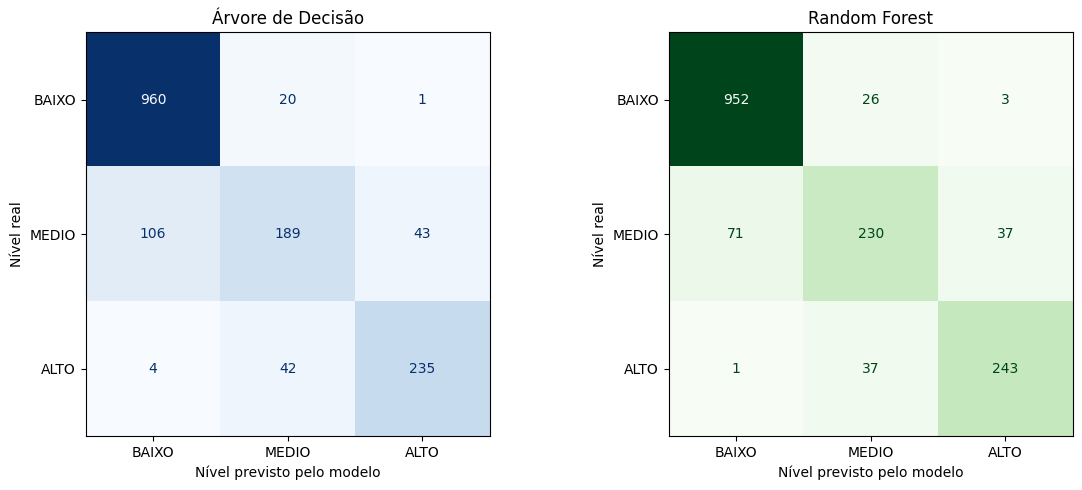

In [18]:
ordem = ["BAIXO", "MEDIO", "ALTO"]
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_arvore, labels=ordem, ax=eixos[0], cmap="Blues", colorbar=False)
eixos[0].set_title("Árvore de Decisão")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_floresta, labels=ordem, ax=eixos[1], cmap="Greens", colorbar=False)
eixos[1].set_title("Random Forest")
for eixo in eixos:
    eixo.set_xlabel("Nível previsto pelo modelo")
    eixo.set_ylabel("Nível real")
plt.tight_layout()
plt.show()

## 9. Importância das correlações

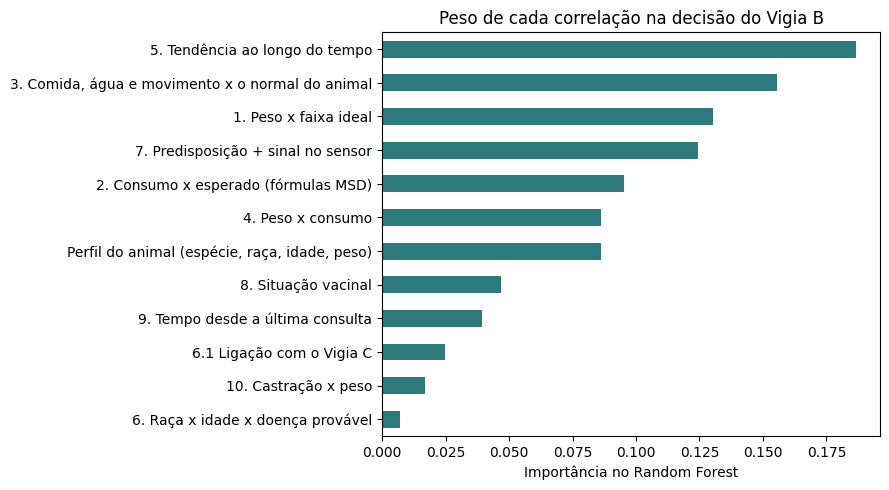

,importância (%)
5. Tendência ao longo do tempo,18.7
"3. Comida, água e movimento x o normal do animal",15.6
1. Peso x faixa ideal,13.0
7. Predisposição + sinal no sensor,12.4
2. Consumo x esperado (fórmulas MSD),9.5
4. Peso x consumo,8.6
"Perfil do animal (espécie, raça, idade, peso)",8.6
8. Situação vacinal,4.7
9. Tempo desde a última consulta,4.0
6.1 Ligação com o Vigia C,2.5


In [19]:
mapa_correlacoes = {
    "desvio_peso": "1. Peso x faixa ideal",
    "castrado_perto_limite": "10. Castração x peso",
    "castrado": "10. Castração x peso",
    "comida_vs_esperado": "2. Consumo x esperado (fórmulas MSD)",
    "agua_vs_esperado": "2. Consumo x esperado (fórmulas MSD)",
    "comida_vs_baseline": "3. Comida, água e movimento x o normal do animal",
    "agua_vs_baseline": "3. Comida, água e movimento x o normal do animal",
    "mov_vs_baseline": "3. Comida, água e movimento x o normal do animal",
    "peso_x_comida": "4. Peso x consumo",
    "tend_comida": "5. Tendência ao longo do tempo",
    "tend_agua": "5. Tendência ao longo do tempo",
    "tend_mov": "5. Tendência ao longo do tempo",
    "idade_risco": "6. Raça x idade x doença provável",
    "predisp_sinal_alterado": "7. Predisposição + sinal no sensor",
    "predisp_forte": "7. Predisposição + sinal no sensor",
    "sinal_tardio": "7. Predisposição + sinal no sensor",
    "vacinas_atrasadas": "8. Situação vacinal",
    "vacina_doenca_regional": "8. Situação vacinal",
    "dias_sem_consulta": "9. Tempo desde a última consulta",
    "alerta_regional": "6.1 Ligação com o Vigia C",
}

importancias = pd.Series(floresta.named_steps["modelo"].feature_importances_, index=colunas_modelo)
agrupado = importancias.groupby(lambda c: mapa_correlacoes.get(c, "Perfil do animal (espécie, raça, idade, peso)")).sum()
agrupado = agrupado.sort_values()

plt.figure(figsize=(9, 5))
agrupado.plot(kind="barh", color="#2c7a7b")
plt.xlabel("Importância no Random Forest")
plt.title("Peso de cada correlação na decisão do Vigia B")
plt.tight_layout()
plt.show()

(agrupado.sort_values(ascending=False) * 100).round(1).to_frame("importância (%)")

## 10. Teste com casos individuais

In [20]:
amostra = X_test.sample(8, random_state=3)
probabilidades = floresta.predict_proba(amostra)

resultado = pd.DataFrame({
    "raca": df.loc[amostra.index, "raca"],
    "idade": df.loc[amostra.index, "idade_anos"],
    "condição simulada": df.loc[amostra.index, "perfil_simulado"],
    "risco real": y_test.loc[amostra.index],
    "risco previsto": floresta.predict(amostra),
    "confiança": probabilidades.max(axis=1).round(2),
})
resultado

,raca,idade,condição simulada,risco real,risco previsto,confiança
799,Persa,10.87,Diabetes mellitus,ALTO,ALTO,0.65
5006,Shar-Pei,10.10,normal,BAIXO,BAIXO,0.98
1421,Maine Coon,6.81,normal,BAIXO,BAIXO,0.96
7998,Shih Tzu,7.86,normal,BAIXO,BAIXO,1.00
5412,Rottweiler,13.05,normal,BAIXO,BAIXO,0.92
6716,Schnauzer Miniatura,2.19,normal,BAIXO,BAIXO,0.82
5515,Azul Russo,8.59,Doença renal policística,ALTO,ALTO,0.88
2058,Shih Tzu,2.83,magreza,BAIXO,BAIXO,0.78


## 11. Nível de risco e causa provável (exemplo: Schnauzer Miniatura)

In [21]:
rng = np.random.default_rng(0)
dias = np.arange(30)
subida = np.clip((dias - 15) / 14, 0, 1)
comida_esp, agua_esp, _, _ = consumo_esperado("Canina", "Schnauzer Miniatura", "M", 8.2, True, None, referencias)
leituras = [{"comida": comida_esp * (1 + 0.4 * s) * rng.normal(1, 0.05),
             "agua": agua_esp * (1 + 0.65 * s) * rng.normal(1, 0.06),
             "movimento": 44 * rng.normal(1, 0.06)} for s in subida]
animal = {"especie": "Canina", "raca": "Schnauzer Miniatura", "sexo": "M", "idade_anos": 10.5,
          "peso_kg": 8.2, "castrado": True, "kcal_kg_racao": None}
features, detalhes = extrair_features(animal, leituras, [], 120, [], referencias)
entrada = pd.DataFrame([features])[FEATURES_CATEGORICAS + FEATURES_NUMERICAS]
print("Nível de risco (modelo):", floresta.predict(entrada)[0],
      f"— confiança {floresta.predict_proba(entrada).max():.2f}")
print("Causa mais provável (regra):", causa_provavel(features, detalhes))
print("Sinais no sensor:", detalhes["sinais"])
print("Doenças compatíveis, em ordem:", [c["doenca"] for c in detalhes["causas_compativeis"]])

Nível de risco (modelo): ALTO — confiança 0.75
Causa mais provável (regra): Síndrome de Cushing (3,0× mais comum na raça)
Sinais no sensor: {'comida': 1, 'agua': 1, 'movimento': 0}
Doenças compatíveis, em ordem: ['Síndrome de Cushing']


## 12. Salvando o modelo

In [22]:
modelo_final = floresta if acc_floresta >= acc_arvore else arvore
nome_final = "Random Forest" if modelo_final is floresta else "Árvore de Decisão"

joblib.dump({
    "modelo": modelo_final,
    "nome": nome_final,
    "arvore": arvore,
    "features_numericas": FEATURES_NUMERICAS,
    "features_categoricas": FEATURES_CATEGORICAS,
    "acuracia_teste": round(max(acc_floresta, acc_arvore), 4),
    "parametros_arvore": melhores_8,
    "parametros_floresta": busca_floresta.best_params_,
}, "modelo_vigia_b.joblib", compress=3)

print(f"Modelo salvo: {nome_final} (acurácia no teste: {max(acc_floresta, acc_arvore):.3f})")

Modelo salvo: Random Forest (acurácia no teste: 0.891)


## 13. Testando o modelo salvo

In [23]:
pacote = joblib.load("modelo_vigia_b.joblib")
modelo_salvo = pacote["modelo"]
print("Modelo carregado:", pacote["nome"])
print(f"Acurácia do modelo carregado no teste: {accuracy_score(y_test, modelo_salvo.predict(X_test)):.3f}")


def avaliar_animal(features):
    """Monta a ficha de um animal e devolve o nível de risco e a confiança."""
    entrada = pd.DataFrame([features])[pacote["features_categoricas"] + pacote["features_numericas"]]
    return modelo_salvo.predict(entrada)[0], modelo_salvo.predict_proba(entrada).max()

Modelo carregado: Random Forest
Acurácia do modelo carregado no teste: 0.891


### Animal de risco ALTO

In [24]:
animal = df.loc[y_test[y_test == "ALTO"].index[0]]
nivel, confianca = avaliar_animal(animal.to_dict())
print(f"{animal['raca']}, {animal['idade_anos']:.1f} anos")
print(f"Previsto: {nivel} (confiança {confianca:.2f}) | Real: {animal['nivel_risco']}")

Rottweiler, 3.1 anos
Previsto: ALTO (confiança 0.54) | Real: ALTO


### Animal de risco BAIXO

In [25]:
animal = df.loc[y_test[y_test == "BAIXO"].index[0]]
nivel, confianca = avaliar_animal(animal.to_dict())
print(f"{animal['raca']}, {animal['idade_anos']:.1f} anos")
print(f"Previsto: {nivel} (confiança {confianca:.2f}) | Real: {animal['nivel_risco']}")

Shih Tzu, 13.7 anos
Previsto: BAIXO (confiança 0.99) | Real: BAIXO


### Animal novo, fora do dataset

In [26]:
nivel, confianca = avaliar_animal(features)
print("Schnauzer Miniatura, 10,5 anos, comendo e bebendo mais nas últimas 2 semanas")
print(f"Previsto: {nivel} (confiança {confianca:.2f})")

Schnauzer Miniatura, 10,5 anos, comendo e bebendo mais nas últimas 2 semanas
Previsto: ALTO (confiança 0.75)
